# Systems of Linear Equations
In this session we will focus on understanding linear functions. Specifically, we will explore the framework of **linear algebra**, which gives us a way to represent and understand the solutions to **systems of linear equations**. A system of linear equations consists of several related *functions* with a shared set of *variables*. Many real-world processes can be modeled using several related linear equations. We begin by exploring a concrete example of a linear system, another term for a system of linear equations, before diving deeper into linear algebra.

> ### Today's lesson
> * **Topic**: Linear systems of equations - our first mathematical topic: linear algebra.
> * **Mathematics (refresher)**: systems of equations, the augmented matrix, row operations, Gaussian elimination.
> * **Python today**: numpy arrays and indexing, `np.array` (2D), `sympy.linsolve`, `np.linalg.solve`.
> * **Remember**: Run the cells from top to bottom. If something behaves strangely: *Runtime → Restart session and run all*.

#### Tutoring vs. Part-time job

Imagine that you have two job opportunities while you study. You can either become a tutor or take a part-time job.

If you choose to become a tutor, you have a weekly base salary of 1000 kr and you get 150 kr per hour for each hour you teach. We can represent this as $y = 1000 + 150x$, where $y$ represents kroner earned per week and $x$ represents tutoring hours per week.

If you choose a part-time job, you have a weekly base salary of 500 kr and you get 200 kr per hour. This can be represented as $y = 500 + 200x$, where $y$ also represents kr earned per week and $x$ represents hours worked per week.

We want to understand which job offer is better. If we know exactly how much we want to earn each week ($y$), we can substitute this value into both equations and solve to identify which job requires us to work fewer hours. If we know exactly how many hours we want to work each week ($x$), we can substitute this value into both equations and solve to identify which job gives us more money for the same amount of hours worked.

**Instead, we want to find out:**
* At what number of working hours can we expect to earn the same amount on both jobs?
* How many hours do we need to work to earn more money at the part-time job than as a tutor?

To answer the first question, we need to find the value where both values are equivalent. Once we know where they cross, we can easily find the answer to the second question.

Let's start by visualizing both of these equations on a plot and getting a visual understanding of where they cross.

* Use numpy.linspace() to generate 1000 evenly spaced values between 0 and 50 and assign them to $x$.
* Transform $x$ using the equation $y = 1000 + 150x$, and assign the result to y1.
* Transform $x$ using the equation $y = 500 + 200x$, and assign the result to y2.
* Generate 2 line plots on the same subplot:
  - One with $x$ on the x-axis and y1 on the y-axis. Set the line color to "gold".
  - One with $x$ on the x-axis and y2 on the y-axis. Set the line color to "blue".

Avoid choosing a value range for the x- and y-axes, and instead let matplotlib choose automatically based on the data.

In [1]:
# Import NumPy as np and Matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(suppress=True)
import matplotlib.pyplot as plt

In [2]:
x = np.linspace(0, 50, num=1000)

In [3]:
x

array([ 0.        ,  0.05005005,  0.1001001 ,  0.15015015,  0.2002002 ,
        0.25025025,  0.3003003 ,  0.35035035,  0.4004004 ,  0.45045045,
        0.5005005 ,  0.55055055,  0.6006006 ,  0.65065065,  0.7007007 ,
        0.75075075,  0.8008008 ,  0.85085085,  0.9009009 ,  0.95095095,
        1.001001  ,  1.05105105,  1.1011011 ,  1.15115115,  1.2012012 ,
        1.25125125,  1.3013013 ,  1.35135135,  1.4014014 ,  1.45145145,
        1.5015015 ,  1.55155155,  1.6016016 ,  1.65165165,  1.7017017 ,
        1.75175175,  1.8018018 ,  1.85185185,  1.9019019 ,  1.95195195,
        2.002002  ,  2.05205205,  2.1021021 ,  2.15215215,  2.2022022 ,
        2.25225225,  2.3023023 ,  2.35235235,  2.4024024 ,  2.45245245,
        2.5025025 ,  2.55255255,  2.6026026 ,  2.65265265,  2.7027027 ,
        2.75275275,  2.8028028 ,  2.85285285,  2.9029029 ,  2.95295295,
        3.003003  ,  3.05305305,  3.1031031 ,  3.15315315,  3.2032032 ,
        3.25325325,  3.3033033 ,  3.35335335,  3.4034034 ,  3.45

In [4]:
len(x)

1000

In [5]:
y1 = 1000 + 150*x

In [6]:
y2 = 500 + 200*x

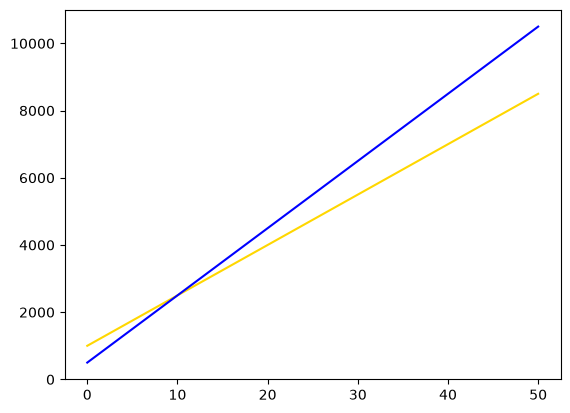

In [7]:
plt.plot(x, y1, color = "gold")
plt.plot(x, y2, color = 'blue')

## Solving a linear system
From the plot we've generated, we can tell that both functions intersect somewhere near $x = 10$

This point, where both equations cross, is known as a **solution** to the system, because substituting $x$ and $y$ into both functions in the system makes them both true. Put another way, plugging the $x$ value of the solution into both functions gives the same $y$ value.

Let's examine how to solve this system manually. Because both functions share the same variables, we can represent one of the variables, for example $y$, in terms of the other variable and solve for the $x$ value. We can then substitute this $x$ value into both equations to determine the $y$ value. This process is known as **solving by elimination** or the **elimination method**. Let's go through how we apply this process to our system.

First, we substitute the first function for $y$ in the second function:


\begin{equation}
\begin{split}
y & = {1000 + 150x} \\
y & = {500 + 200x}
\end{split}
\rightarrow 1000 - 500 = 200x - 150x \rightarrow 500 = 50x \rightarrow 10 = x
\end{equation}

Note that order doesn't matter, and we could equally have substituted the second function for $y$ in the first function. Now that we know $x = 10$, we can substitute this into both equations to determine $y$.

\begin{equation}
\begin{split}
y & = {1000 + 150(10)} \\
y & = {500 + 200(10)}
\end{split}
\rightarrow
\begin{split}
y & = 2500 \\
y & = 2500
\end{split}
\end{equation}

The solution to our system is (10, 2500). This means that if we work exactly 10 hours per week, we earn the same amount on both jobs: 2500.

While we can solve a linear system like this manually using arithmetic, we can't use the same technique to solve much more complex systems. Many real-world processes are modeled using far more than 2 variables and functions, and it's impossible to solve these by hand. These types of systems can be solved using linear algebra, using a variation of arithmetic elimination called **Gaussian elimination**. In what follows, we go through how to perform Gaussian elimination to find a solution to our linear system.

## Matrix elimination
Linear algebra gives us a way to represent a linear system compactly, known as a **matrix**, along with a set of rules for manipulating this representation, also known as an **algebra**. A matrix uses rows and columns to represent only the coefficients of a linear system, similar to how data is represented in a spreadsheet or a dataframe. Before we can represent our system as a matrix, we need to rearrange each of our functions into **general form**.

From gymnasium (Danish high school) you know that linear functions are often written in slope-intercept form:
> $y = ax + b$

In linear algebra we usually represent linear functions in general form:
> $Ax + By = c$

In general form, the variables and their coefficients are on the *left*-hand side, while the constant term is on the *right*-hand side. We can switch from slope-intercept form to general form by rearranging:
> $ax − y = −b$

Here's what the first function looks like in general form:
> $150x − y = -1000$

Here's what the second function looks like in general form:
> $200x − y = -500$




To represent both linear functions in a system, we use an **augmented matrix**:



$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$


In an augmented matrix, the coefficients from the left-hand side of the functions are on the left side of the bar (|), while the constants from the right-hand side of the functions are on the right side. An augmented matrix allows us to represent a linear system using only the actual coefficients and constants.

Here's a summary of the 3 different representations of the linear system we've just discussed:

**slope-intercept form**
$$
y  = 1000 + 150x \\
y  = 500 + 200x
$$

**general form**

 $$150x − y = -1000\\
 200x − y = -500 $$

**augmented matrix**

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

In the next part, we'll go through how to represent this augmented matrix in **NumPy**. In later sessions we'll learn the rules of matrix manipulation and how to apply them to arrive at the system's solution.

### Matrices in Python
You know numpy arrays as rows of numbers - now we're adding a dimension: rows *and* columns. To represent an augmented matrix we can use the `numpy.array()` function and pass each row as a list, from the top row to the bottom row. The following code represents a matrix with 2 rows and 3 columns, containing only 0s:

In [8]:
random_matrix_with_many_0s = np.array([
                         [0, 0, 0],
                         [0, 0, 0]
])

In [9]:
rndom_matrix_with_many_0s

NameError: name 'rndom_matrix_with_many_0s' is not defined

A numpy matrix (array) has a shape, and there are several built-in functions you can use to manipulate a matrix.

In [10]:
random_matrix_with_many_0s.shape

(2, 3)

let's use our values from the case

here we can see that there are 2 rows and 3 columns
Now create a NumPy 2d **array** of our augmented case matrix "`matrix_one`"

In [11]:
# Solution of a linear system in general form
matrix_one = np.array([
                         [150, -1, -1000],
                         [200, -1, -500]
], dtype=np.float32)
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

`np.array` or `np.asarray` can also be used to form a matrix starting from a `pandas` dataframe.
Pandas dataframes themselves also have a function called `to_numpy` - which does the same thing.
In other words, it's very easy to go from tabular data to a matrix and back again, where you can use `pd.DataFrame` to turn a matrix into a dataframe.

In [12]:
import pandas as pd

In [13]:
df = pd.DataFrame([[150, -1, -1000],
                   [200, -1, -500]], columns=['v1','v2','v3'])
df

,v1,v2,v3
0,150,-1,-1000
1,200,-1,-500


In [14]:
df.to_numpy()

array([[  150,    -1, -1000],
       [  200,    -1,  -500]])

In this course we won't, as a rule, be working with pandas and dataframes, but just like numpy, it's a fundamental tool for doing data science in Python, and it will be introduced and covered in later courses.

### Matrix solution in Python
The important question now is, how do we arrive at the same solution as we did earlier with arithmetic? Earlier we used arithmetic to calculate the solution to the system and represented it as a coordinate pair: (10, 2500).

When working with the matrix representation, the solution can be written as:

$$
\left[\begin{array}{rr|r}
1 & 0 & 10 \\
0 & 1 & 2500
\end{array}\right]
$$


The intuition can be seen here:


**If this**

$$
\begin{align}
150x − y = -1000\\
200x − y = -500 \\
\end{align}
$$

**can be translated to this**

$$
\left[
  \begin{matrix}
    150 & -1 \\
    200 & -1 \\
  \end{matrix}
  \left|
    \,
    \begin{matrix}
      -1000  \\
      -500  \\
    \end{matrix}
  \right.
\right]
$$

**then we could write**

$$
\left[\begin{array}{rr|r}
1 & 0 & 10 \\
0 & 1 & 2500
\end{array}\right]
$$

**as**

$$
\begin{align}
1x + 0y = 10\\
0x + 1y = 2500 \\
\end{align}
$$




To solve a linear system, we need to carry out a series of transformations to try to develop the matrix into this form (where the solution is presented). However, not all linear systems have solutions, and we will look at this more closely later in this course.

#### Row operations

To preserve the relationships in the linear system, we can only use the following row operations:

1. rows can be swapped

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow \text{Swap } R_1\  \& \  R_2$$

$$
\left[\begin{array}{rr|r}
200 & -1 & -500\\
150 & -1 & -1000
\end{array}\right]
$$

2. Any row can be multiplied by a nonzero constant:

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow 2·R_1\  3·R_2 $$

$$
\left[\begin{array}{rr|r}
300 & -2 & -2000\\
600 & -3 & -1500
\end{array}\right]
$$

3. Any row can be added to another row

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000 \\
200 & -1 & -500
\end{array}\right]
$$

$$\downarrow R_2 = R_1 + R_2 $$

$$
\left[\begin{array}{rr|r}
150 & -1 & -1000\\
350 & -2 & -1500
\end{array}\right]
$$

Although these might seem new, the row operations are the same permitted operations we can perform when the functions are in equation form. Before we dive into how we solve our linear system using these row operations, let's first practice performing these transformations in NumPy.

To swap 2 rows in a NumPy ndarray object, we need to use double bracket notation to specify the change in order:

In [15]:
matrix = np.array([
                     [20, 4],
                     [66, 7]
])

In [16]:
matrix

array([[20,  4],
       [66,  7]])

In [17]:
# Show R1
matrix[0,:]

array([20,  4])

In [18]:
# Show R2
matrix[1,:]

array([66,  7])

In [19]:
# Show C1
matrix[:,0]

array([20, 66])

In [20]:
# Show everything
matrix

array([[20,  4],
       [66,  7]])

In [21]:
# Swap R1 & R2
matrix_swap = matrix[[1,0],:]

In [22]:
matrix_swap

array([[66,  7],
       [20,  4]])

To multiply a row by a nonzero constant, we select the row, use the * operator to multiply all the values by a scalar value, and then assign the transformed row back:

In [23]:
# Multiply the second row by 2:
matrix[1] = 2*matrix[1]

To add one row to another row, we add both rows together and then assign the result back to the row we want to overwrite:

In [24]:
# Add the first row to the second:
matrix[1] = matrix[1] + matrix[0]

Note that you cannot multiply or divide by other rows.

#### Echelon form
To find the solutions in a matrix, there are two main steps we need to take. The first step is to rearrange the matrix into **echelon form**. In this form, the values on the diagonal positions are all equal to 1, and the values below the diagonal are all equal to 0.

$$
\left[\begin{array}{rr|r}
1 & ? & ? \\
0 & 1 & ?
\end{array}\right]
$$

In [25]:
matrix_one = np.array([
                         [150, -1, -1000],
                         [200, -1, -500]
], dtype=np.float32)
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

First, we can divide the first row by 150, so that the diagonal value in the first row becomes 1

$$R_1 = R_1 / 150$$

In [26]:
matrix_one

array([[  150.,    -1., -1000.],
       [  200.,    -1.,  -500.]], dtype=float32)

In [27]:
matrix_one[0] = matrix_one[0]/150

In [28]:
matrix_one

array([[   1.        ,   -0.00666667,   -6.6666665 ],
       [ 200.        ,   -1.        , -500.        ]], dtype=float32)

Next, let's subtract 200 times the first row from the second row:

In [29]:
matrix_one[1] = matrix_one[1] - 200*matrix_one[0]

In [30]:
matrix_one

array([[  1.        ,  -0.00666667,  -6.6666665 ],
       [  0.        ,   0.33333337, 833.33325   ]], dtype=float32)

Let's carry out the final transformations to bring the matrix fully into reduced echelon form, where the solution can be read off directly

In [31]:
matrix_one[1] = matrix_one[1] * (1/matrix_one[1,1])

In [32]:
matrix_one

array([[   1.        ,   -0.00666667,   -6.6666665 ],
       [   0.        ,    1.        , 2499.9995    ]], dtype=float32)

In [33]:
matrix_one[0] = matrix_one[0] - (matrix_one[1] * matrix_one[0,1])

In [34]:
matrix_one

array([[   1.      ,    0.      ,    9.999998],
       [   0.      ,    1.      , 2499.9995  ]], dtype=float32)

$$\left[\begin{array}{rr|r}
1 & 0 & ? \\
0 & 1 & ?
\end{array}\right]$$

Now we can say that $x = 10$ and $y = 2500$

In [35]:
# we can use SymPy to check our calculations

from sympy import symbols, solve, linsolve, Matrix # import what we need from SymPy
from sympy.solvers.solveset import linsolve # import the linalg solver

x, y = symbols('x, y') # define our symbols

linsolve(Matrix(([150,    -1, -1000], [200, -1, -500])), (x, y)) # define the matrix and what to solve for

{(10, 2500)}

### Several independent variables
In most real-world situations, the dependent variable is connected to several independent variables, not just a single x. To represent these functions, we need to work with another version of general form:

$a_1x_1 + a_2x_2 + a_3x_3 + … + a_nx_n = c$


In this form, $a_1…a_n$ are the coefficients and $c$ is a constant value.

$$
\begin{align*}2x_1 + 5x_2 + 2x_3 &=  - 38\\  3x_1 - 2x_2 + 4x_3 &= 17\\   - 6x_1 + x_2 - 7x_3 &=  - 12\end{align*}
$$


$$\left[\begin{array}{rrr|r}
2 & 5 & 2 & -38\\
3 & -2 & 4 & 17\\
-6 & 1 & -7 & -12
\end{array}\right]$$


In [36]:
matrix_3x4 = np.array([[2,5,2,-38],
                         [3,-2,4,17],
                         [-6,1,-7,-12]] , dtype = np.float32)

In [37]:
x1, x2, x3 = symbols('x1, x2, x3') # which here could be anything you like...but let's use x1...n

linsolve(Matrix(matrix_3x4), (x1, x2, x3))

{(3.0, -8.0, -2.0)}

If we have a system with more than 3 variables, we can't easily visualize it. In addition, performing Gaussian elimination becomes much more problematic. Over the next few sessions we will develop more of the theory and geometric intuition behind linear algebra and build on this to solve these more complex linear systems.

# **Key concepts**

* Linear algebra gives us a way to represent and understand solutions to systems of linear equations. We represent linear equations in general form $Ax + By = c$.

* A system of linear equations consists of several related functions with a shared set of variables. The point where the equations cross is known as a solution to the system.

* The elimination method involves representing one of our variables in terms of a desired variable and substituting the equation that is in terms of the desired variable.

  * Suppose we have the equations $y = 1000 + 30x$ and $y = 100 + 50x$. Since both equal y, we can substitute the second function for the first. Here are the steps for solving our example using the elimination method:
    * $1000 + 30x = 100 + 50x$
    * $900 = 20x$
    * $45 = x$

* A matrix uses rows and columns to represent only the coefficients of a linear system, similar to how data is represented in a spreadsheet or a DataFrame.

* Gaussian elimination is used to solve systems of equations modeled by many variables and equations.

* In an augmented matrix, the coefficients from the left-hand side of the function are on the left side of the bar (|), while the constants from the right-hand side of the function are on the right side.

* To preserve the relationships in the linear system, we can use the following row operations:
  * Any row can be swapped with another.
  * Any row can be multiplied by a nonzero constant.
  * Any row can be added to another row.